In [1]:
import numpy as np
import uxarray as ux
from matplotlib import pyplot as plt
from scipy.interpolate import griddata, RegularGridInterpolator
import pygeode as pyg
import os, glob
from jfunctions import *

%matplotlib widget

save = False

In [2]:
data_dir = '/store/ATMOS/cwp29/mpas-a/data/ape_test/120km_2/'
grid_path = data_dir + 'x1.40962.grid.nc'

#data_paths = sorted(glob.glob(data_dir+'diag.*.nc'))
#ds = ux.open_mfdataset(grid_path, data_paths, combine="nested", concat_dim="Time")

#dsh = ux.open_dataset(grid_path, run_dir+'latlon_hist.nc')

dsd = pyg.open(data_dir+'latlon_diag.nc')
dsh = pyg.open(data_dir+'latlon_hist.nc')

In [3]:
def fix_time(var, step=3):
    ''' Replaces loaded 'Time' axis with a PyGeode standard time axixs.'''
    time_axis = pyg.standardtimen('00:00:00 1 Mar 2000', n=len(var.Time), step=step, units='hours')
    return var.replace_axes({'Time': time_axis})

def daily_data(var, n=8):
    ''' Sums every n steps in var.'''
    return np.add.reduceat(var[:], np.arange(0, len(var.time), n))

In [4]:
# rainc, rainnc contain accumulated rainfall from simulation start to given timestep
precip = dsd.rainnc + dsd.i_rainnc*100. + dsd.rainc + dsd.i_rainc*100.

precip_rate = np.gradient(precip.mean('lat', 'lon')[::8])

precip_water = fix_time(dsd.precipw).mean('lat', 'lon').dailymean()[:]

/tmp/ipykernel_8034/2973800752.py:13: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


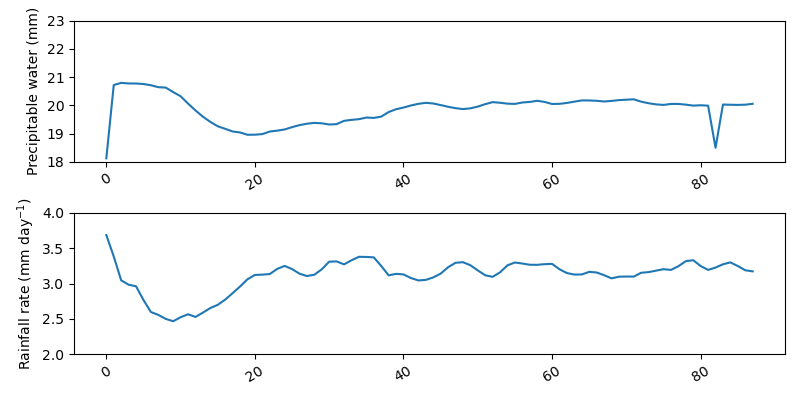

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(8, 4), constrained_layout=True)
ax[0].plot(precip_water)
ax[0].set_ylim(18, 23)
ax[0].set_ylabel(r"Precipitable water (mm)")

ax[1].plot(precip_rate)
ax[1].set_ylim(2, 4)
ax[1].set_ylabel(r"Rainfall rate (mm day$^{-1}$)")

for a in ax:
    a.tick_params('x', rotation=30)

plt.tight_layout()

if save: save_fig(fig, '/home/cwp29/tmp/mpas/rain_stats.png', dpi=300)

In [6]:
lats = dsd.latitude
lons = dsd.longitude

ndays = 14.
dt = 3. # hours
idx = int(ndays * 24./dt)
print(idx)
ubar = dsd.uzonal_isobaric(i_Time = (-1-idx, -1)).mean('longitude', 'Time')[:]
vbar = dsd.umeridional_isobaric(i_Time = (-1-idx, -1)).mean('longitude', 'Time')[:]
omgbar = dsd.omg_isobaric(i_Time = (-1-idx, -1)).mean('longitude', 'Time')[:]
rhbar = dsd.rh_isobaric(i_Time = (-1-idx, -1)).mean('longitude', 'Time')[:]
Tbar = dsd.t_isobaric(i_Time = (-1-idx, -1)).mean('longitude', 'Time')[:]

112


/alt/applic/user-maint/cwp29/Conda/envs/python/lib/python3.11/site-packages/pygeode/view.py:283: UserWarning: <Var 'uzonal_isobaric'> is supposed to return a float32, but is returning float64
  warn ("%s is supposed to return a %s, but is returning %s"%(repr(var),var.dtype.name,values.dtype.name))
/alt/applic/user-maint/cwp29/Conda/envs/python/lib/python3.11/site-packages/pygeode/view.py:283: UserWarning: <Var 'umeridional_isobaric'> is supposed to return a float32, but is returning float64
  warn ("%s is supposed to return a %s, but is returning %s"%(repr(var),var.dtype.name,values.dtype.name))
/alt/applic/user-maint/cwp29/Conda/envs/python/lib/python3.11/site-packages/pygeode/view.py:283: UserWarning: <Var 'omg_isobaric'> is supposed to return a float32, but is returning float64
  warn ("%s is supposed to return a %s, but is returning %s"%(repr(var),var.dtype.name,values.dtype.name))
/alt/applic/user-maint/cwp29/Conda/envs/python/lib/python3.11/site-packages/pygeode/view.py:283: User

(17, 360)


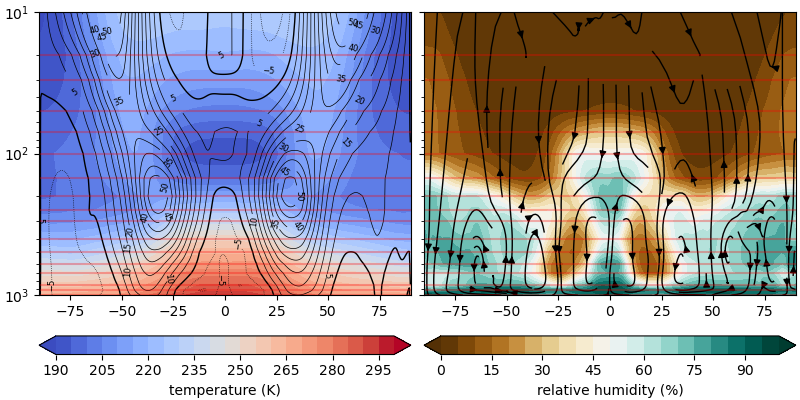

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharey=True, constrained_layout=True)

pres = np.array([1000, 2000, 3000, 5000, 7000, 10000, 15000, 20000, 25000, 30000, 40000, 50000, 60000, 70000, 85000, 92500, 100000], dtype=np.float64)
pres /= 100

T_im = ax[0].contourf(lats, pres, Tbar, levels=np.arange(190, 305, 5), extend='both', cmap='coolwarm')
u_im_neg = ax[0].contour(lats, pres, ubar, levels=np.arange(-20, 0, 5), colors='k', linestyles=':', linewidths=0.5)
u_im_zero = ax[0].contour(lats, pres, ubar, levels=[0], colors='k', linewidths=1)
u_im_pos = ax[0].contour(lats, pres, ubar, levels=np.arange(5, 55, 5), colors='k', linewidths=0.5)
ax[0].clabel(u_im_pos, u_im_pos.levels, fontsize=6)
ax[0].clabel(u_im_neg, u_im_neg.levels, fontsize=6)
ax[0].invert_yaxis()
ax[0].set_yscale('log')
fig.colorbar(T_im, ax=ax[0], location='bottom', label="temperature (K)")

import scipy.interpolate as intp

print(vbar.shape)
xi = np.linspace(lats.min(), lats.max(), len(lats))
yi = np.linspace(pres.min(), pres.max(), len(pres))

X, Y = np.meshgrid(xi, yi)

U = intp.interpn((lats, pres), vbar.T, (X, Y))
V = intp.interpn((lats, pres), omgbar.T, (X, Y))

rh_im = ax[1].contourf(lats, pres, rhbar, levels=np.arange(0, 105, 5), extend='both', cmap='BrBG')
ax[1].streamplot(X, Y, U/111111., V/100., color='k', linewidth=1, density=1)
fig.colorbar(rh_im, ax=ax[1], location='bottom', label="relative humidity (%)")

plevs = True

for a in ax:
    a.set_xlim(-90, 90)
    a.set_ylim(1000, 10)
    if plevs:
        for p in pres:
            a.axhline(p, color='r', alpha=0.3)

if save: save_fig(fig, '/home/cwp29/tmp/mpas/temp_relhum.png', dpi=300)

In [8]:
dzeta_dz = dsh.zz[:, 0, 0]
z = dsh.zgrid[:, 0, 0]
dz = z[1:] - z[:-1]
dzeta = dzeta_dz * dz

def vert_integral(var, axis=0):
    ''' Compute vertical integral, assuming that first index is vertical coordinate.'''
    return np.sum(var[:] * dzeta[:, np.newaxis] / dzeta_dz[:, np.newaxis], axis=axis)

# calculate moist air density
rho_moist = dsh.rho * (1 + dsh.qc + dsh.qv + dsh.qr + dsh.qi + dsh.qg + dsh.qs)

qlw = dsh.qc + dsh.qr # both cloud and rain water

integrand = (rho_moist * qlw).mean('Time', 'lon') # averages first for memory purposes
lwp_zonal = vert_integral(integrand)

integrand = (rho_moist * dsh.qi).mean('Time', 'lon') # averages first for memory purposes
ip_zonal = vert_integral(integrand)

KeyboardInterrupt: 

In [ ]:
precip_rate_zonal = np.mean(np.gradient(precip.mean('lon')[:][::8], axis=0), axis=0)

In [ ]:
fig, ax = plt.subplots(3, 1, figsize=(8, 8), constrained_layout='True')

ax[0].plot(lats, precip_rate_zonal)
ax[0].set_ylabel("Precipitation rate (mm day$^{-1}$)")

ax[1].plot(lats, lwp_zonal)
ax[1].set_ylabel("Cloud liquid water path")

ax[2].plot(lats, ip_zonal)
ax[2].set_ylabel("Cloud ice path")

for a in ax:
    a.set_xlim(-90, 90)

<Dataset>:
Vars:
  mslp                  (Time,latitude,longitude)              (702,360,720)
  relhum_50hPa          (Time,latitude,longitude)              (702,360,720)
  relhum_100hPa         (Time,latitude,longitude)              (702,360,720)
  relhum_200hPa         (Time,latitude,longitude)              (702,360,720)
  relhum_250hPa         (Time,latitude,longitude)              (702,360,720)
  relhum_500hPa         (Time,latitude,longitude)              (702,360,720)
  relhum_700hPa         (Time,latitude,longitude)              (702,360,720)
  relhum_850hPa         (Time,latitude,longitude)              (702,360,720)
  relhum_925hPa         (Time,latitude,longitude)              (702,360,720)
  dewpoint_50hPa        (Time,latitude,longitude)              (702,360,720)
  dewpoint_100hPa       (Time,latitude,longitude)              (702,360,720)
  dewpoint_200hPa       (Time,latitude,longitude)              (702,360,720)
  dewpoint_250hPa       (Time,latitude,longitude)          